# Cat and Dog Facial Feature Classification 

In [2]:
#This cell finds the training labels CSV file in the attached competition data and displays its location
from pathlib import Path

label_files = list(Path("/kaggle/input").rglob("train_labels.csv"))

print("Training label files found:", len(label_files))
for path in label_files:
    print(path)
    

Training label files found: 1
/kaggle/input/datasets/nkw3744/cat-and-dog-facial-feature-classification/train_labels.csv


In [3]:
# Load the training labels, preserve leading zeros in image IDs, and display the first five rows.
import pandas as pd

labels_path = label_files[0]
labels = pd.read_csv(labels_path, dtype={"image_id": str})

print("Number of labelled images:", len(labels))
display(labels.head())

Number of labelled images: 63660


,image_id,class
0,00001,DogEye
1,00002,DogMouth
2,00003,DogFace
3,00004,DogNose
4,00005,DogNose


In [4]:
# Check that every training label has a matching JPG image.
data_dir = labels_path.parent
first_filename = labels["image_id"].iloc[0] + ".jpg"

train_folders = [
    folder for folder in data_dir.rglob("train")
    if folder.is_dir() and (folder / first_filename).is_file()
]

if len(train_folders) != 1:
    raise ValueError("Could not identify one training image folder.")

train_dir = train_folders[0]
image_paths = labels["image_id"].map(
    lambda image_id: train_dir / f"{image_id}.jpg"
)
missing_images = image_paths.map(lambda path: not path.is_file())

print("Training images checked:", len(image_paths))
print("Missing training images:", missing_images.sum())

Training images checked: 63660
Missing training images: 0


In [5]:
# Count the training images in each class.
class_counts = labels["class"].value_counts().sort_index()

print("Training images per class:")
display(class_counts.rename("image_count").to_frame())

Training images per class:


,image_count
class,
CatEye,13884
CatFace,6942
CatMouth,6942
CatNose,6942
DogEye,11580
DogFace,5790
DogMouth,5790
DogNose,5790


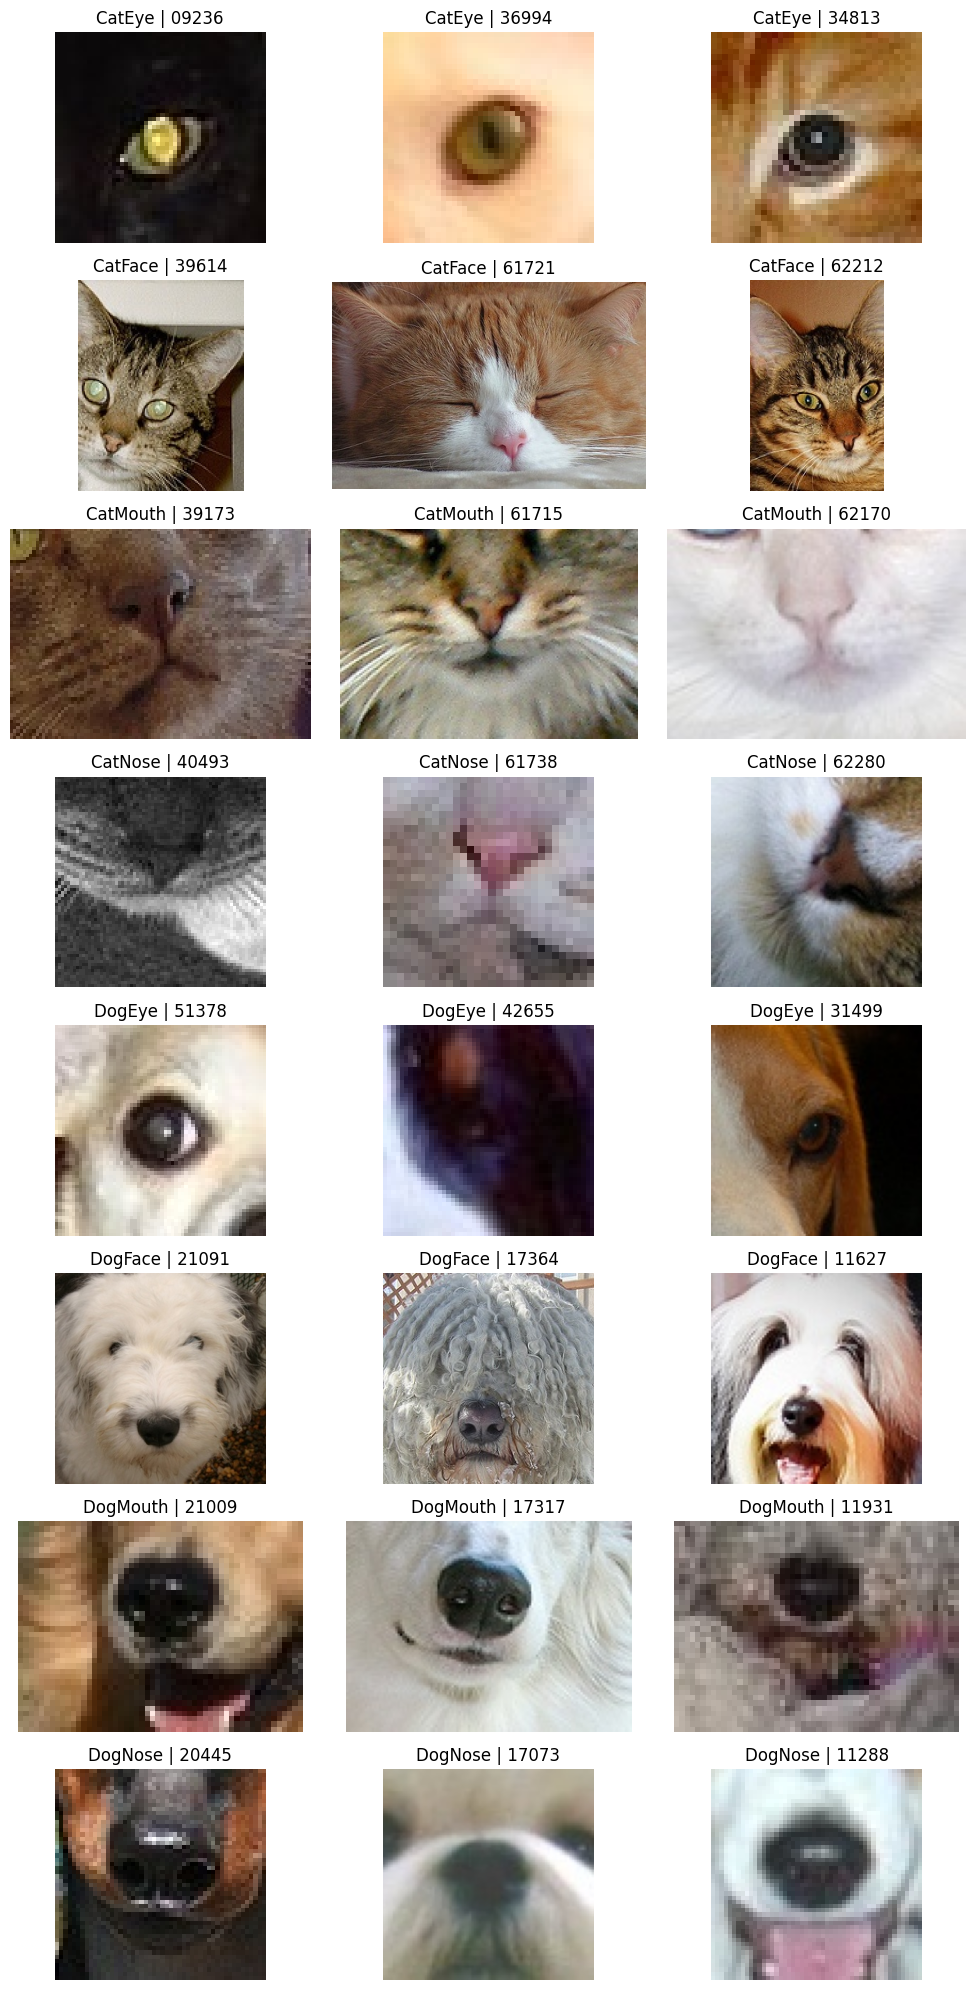

In [19]:
# Display three randomly selected training images from each class.
import matplotlib.pyplot as plt
from PIL import Image

class_names = sorted(labels["class"].unique())
fig, axes = plt.subplots(len(class_names), 3, figsize=(10, 20))

for row, class_name in enumerate(class_names):
    examples = labels.loc[
        labels["class"] == class_name
    ].sample(n=3, random_state=42)

    for col, image_id in enumerate(examples["image_id"]):
        image_path = train_dir / f"{image_id}.jpg"

        with Image.open(image_path) as image:
            axes[row, col].imshow(image.convert("RGB"))

        axes[row, col].set_title(f"{class_name} | {image_id}")
        axes[row, col].axis("off")

plt.tight_layout()
plt.show()

In [7]:
# Check training image sizes and record any images that cannot be fully read.
from tqdm.auto import tqdm

image_records = []
unreadable_images = []

for image_id, image_path in tqdm(
    zip(labels["image_id"], image_paths),
    total=len(labels),
    desc="Checking training images"
):
    try:
        with Image.open(image_path) as image:
            image.load()
            image_records.append({
                "image_id": image_id,
                "width": image.width,
                "height": image.height,
                "mode": image.mode
            })
    except (OSError, ValueError) as error:
        unreadable_images.append({
            "image_id": image_id,
            "error": str(error)
        })

image_info = pd.DataFrame(image_records)
unreadable_info = pd.DataFrame(
    unreadable_images, columns=["image_id", "error"]
)

print("Successfully read:", len(image_info))
print("Unreadable images:", len(unreadable_info))
display(image_info[["width", "height"]].describe())
display(image_info["mode"].value_counts())

if not unreadable_info.empty:
    display(unreadable_info)

Checking training images:   0%|          | 0/63660 [00:00<?, ?it/s]

Successfully read: 63660
Unreadable images: 0


,width,height
count,63660.000000,63660.000000
mean,113.095209,109.737857
std,98.491801,101.911146
min,4.000000,4.000000
25%,54.000000,50.000000
50%,84.000000,80.000000
75%,138.000000,130.000000
max,2219.000000,2219.000000


mode
RGB    63660
Name: count, dtype: int64

In [8]:
# Hash training image pixels to identify exact duplicates and conflicting labels.
import hashlib

image_hashes = []

for image_path in tqdm(image_paths, desc="Checking exact duplicates"):
    with Image.open(image_path) as image:
        rgb = image.convert("RGB")
        fingerprint = hashlib.sha256()
        fingerprint.update(f"{rgb.width},{rgb.height}:".encode())
        fingerprint.update(rgb.tobytes())
        image_hashes.append(fingerprint.hexdigest())

labels["image_hash"] = image_hashes

hash_groups = labels.groupby("image_hash").agg(
    image_count=("image_id", "size"),
    class_count=("class", "nunique")
)

duplicate_groups = hash_groups[hash_groups["image_count"] > 1]
conflicting_groups = hash_groups[hash_groups["class_count"] > 1]

print("Exact duplicate groups:", len(duplicate_groups))
print("Images in duplicate groups:", duplicate_groups["image_count"].sum())
print("Extra copies:", (duplicate_groups["image_count"] - 1).sum())
print("Groups with conflicting class labels:", len(conflicting_groups))

Checking exact duplicates:   0%|          | 0/63660 [00:00<?, ?it/s]

Exact duplicate groups: 15
Images in duplicate groups: 30
Extra copies: 15
Groups with conflicting class labels: 0


In [9]:
# Create a new training-label table that keeps the first copy of each identical image and leaves out any extra copies, without deleting image files.
clean_labels = labels.drop_duplicates(
    subset="image_hash", keep="first"
).copy().reset_index(drop=True)

print("Original rows:", len(labels))
print("Extra copies excluded:", len(labels) - len(clean_labels))
print("Remaining rows:", len(clean_labels))

assert clean_labels["image_hash"].is_unique

Original rows: 63660
Extra copies excluded: 15
Remaining rows: 63645


In [10]:
# Split the cleaned labels into 80% for learning and 20% for validation.
from sklearn.model_selection import train_test_split

train_labels, val_labels = train_test_split(
    clean_labels,
    test_size=0.20,  # Hold back 20% of the images for validation.
    random_state=42,  # Repeat the same split when using the same input data.
    stratify=clean_labels["class"]  # Keep similar class proportions in both groups.
)

# Give each table a fresh row index starting at zero.
train_labels = train_labels.reset_index(drop=True)
val_labels = val_labels.reset_index(drop=True)

# Stop with an error if an identical image fingerprint appears in both groups.
assert set(train_labels["image_hash"]).isdisjoint(val_labels["image_hash"])

print("Training images:", len(train_labels))
print("Validation images:", len(val_labels))

# Display the number of images from each class in each group.
display(pd.DataFrame({
    "training": train_labels["class"].value_counts(),
    "validation": val_labels["class"].value_counts()
}).sort_index())

Training images: 50916
Validation images: 12729


,training,validation
class,,
CatEye,11102,2775
CatFace,5553,1389
CatMouth,5553,1388
CatNose,5553,1388
DogEye,9261,2315
DogFace,4630,1158
DogMouth,4632,1158
DogNose,4632,1158


In [11]:
# Save the training and validation lists so we can reuse the same split later.
output_dir = Path("/kaggle/working/splits")
output_dir.mkdir(parents=True, exist_ok=True)

train_labels.to_csv(output_dir / "train_labels.csv", index=False)
val_labels.to_csv(output_dir / "val_labels.csv", index=False)

# Read image IDs back as text to preserve their leading zeros.
saved_train = pd.read_csv(
    output_dir / "train_labels.csv", dtype={"image_id": str}
)
saved_val = pd.read_csv(
    output_dir / "val_labels.csv", dtype={"image_id": str}
)

# Check that the saved files contain the same rows and values as our tables.
pd.testing.assert_frame_equal(saved_train, train_labels)
pd.testing.assert_frame_equal(saved_val, val_labels)

print("Saved and verified training rows:", len(saved_train))
print("Saved and verified validation rows:", len(saved_val))
print("Saved in:", output_dir)

Saved and verified training rows: 50916
Saved and verified validation rows: 12729
Saved in: /kaggle/working/splits


In [13]:
# Give each class a number from 0 to 7 so the model can learn its label.
class_names = sorted(train_labels["class"].unique())
class_to_index = {
    class_name: number
    for number, class_name in enumerate(class_names)
}

# Add the numerical labels while keeping the original class names.
train_labels["label"] = train_labels["class"].map(class_to_index)
val_labels["label"] = val_labels["class"].map(class_to_index)

# Check that all eight classes are present and every row has a numerical label.
assert len(class_names) == 8
assert train_labels["label"].notna().all()
assert val_labels["label"].notna().all()

print("Class numbers:")
for class_name, number in class_to_index.items():
    print(f"{number}: {class_name}")

display(train_labels[["image_id", "class", "label"]].head())

Class numbers:
0: CatEye
1: CatFace
2: CatMouth
3: CatNose
4: DogEye
5: DogFace
6: DogMouth
7: DogNose


,image_id,class,label
0,26977,CatNose,3
1,43790,DogMouth,6
2,60045,CatEye,0
3,47430,DogEye,4
4,50148,DogMouth,6


In [14]:
# Load PyTorch and its image tools, then show the installed versions.
import torch
import torchvision
from torchvision import transforms
from torch.utils.data import Dataset, DataLoader

print("PyTorch version:", torch.__version__)
print("Torchvision version:", torchvision.__version__)

# Confirm that the earlier label-encoding cell has run for both sets.
assert "label" in train_labels.columns
assert "label" in val_labels.columns

print("Training and validation labels are ready.")

PyTorch version: 2.11.0+cpu
Torchvision version: 0.26.0+cpu
Training and validation labels are ready.


,group,image_id,class,width,height,width_to_height,pixel_count
0,Widest,48016,CatMouth,84,10,8.400000,840
1,Widest,35094,CatMouth,186,39,4.769231,7254
2,Tallest,49312,CatFace,153,380,0.402632,58140
3,Tallest,58161,CatFace,152,357,0.425770,54264
4,Smallest,36018,CatNose,4,4,1.000000,16
5,Smallest,51449,CatMouth,6,4,1.500000,24
6,Largest,47668,DogFace,2190,2070,1.057971,4533300
7,Largest,52414,DogFace,1786,1787,0.999440,3191582


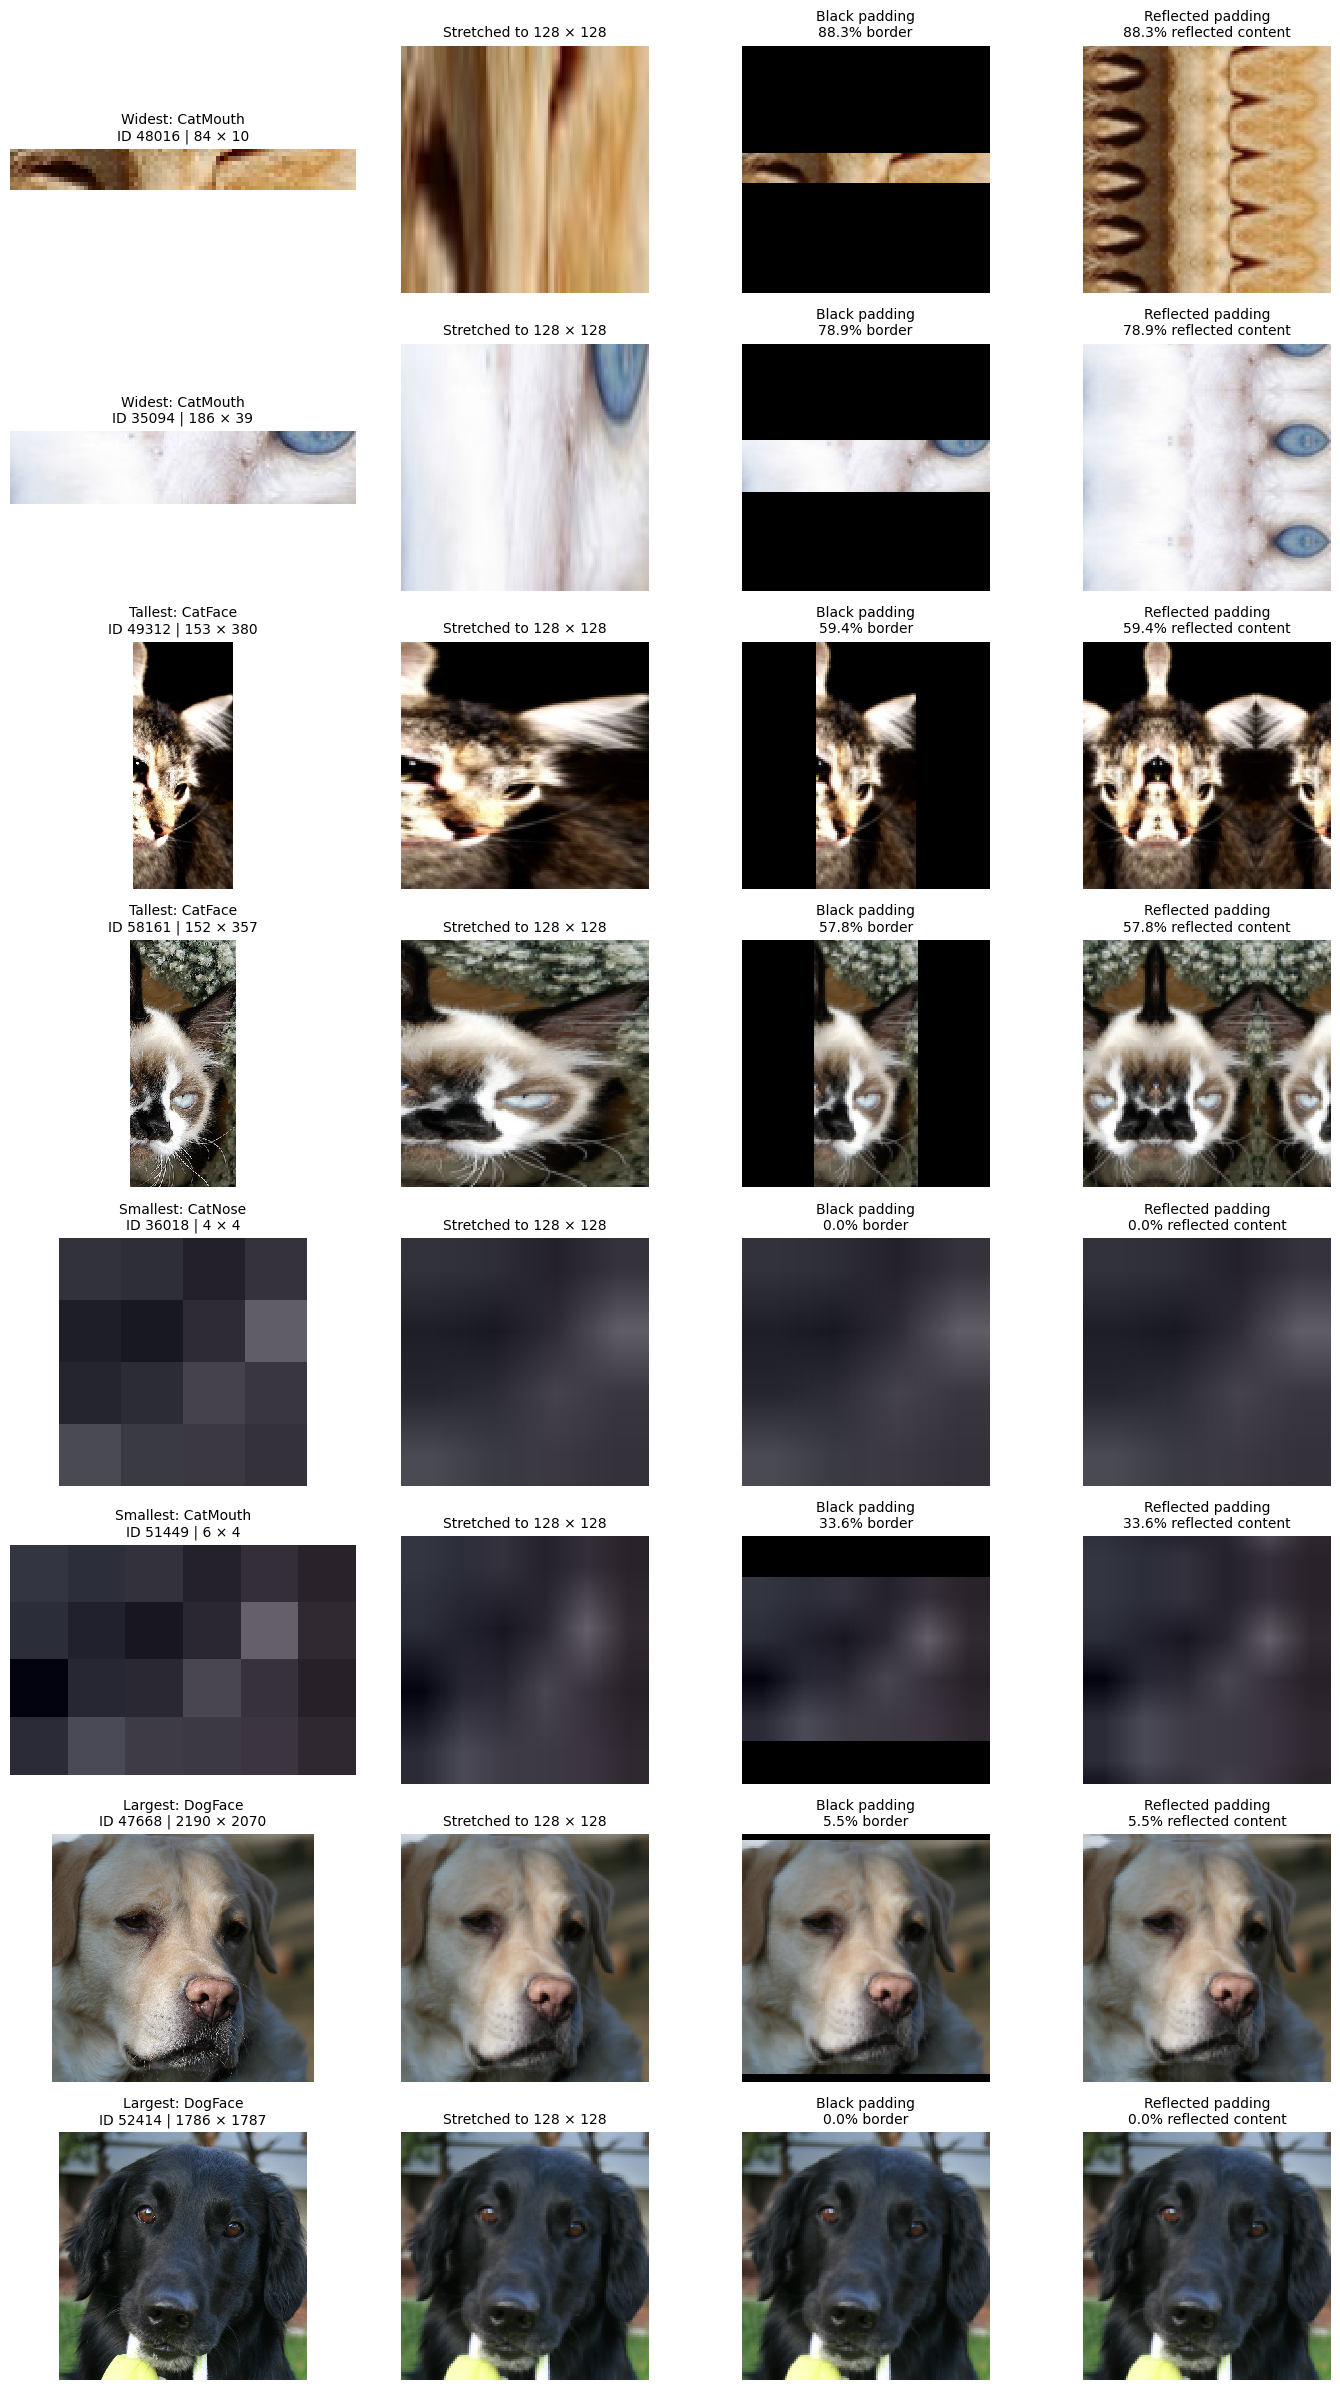

In [20]:
# Select extreme image shapes and sizes, then compare three resizing methods.
# Load the tools used to prepare tables and display image comparisons.
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image, ImageOps
# Use complete recorded dimensions rather than scanning all images again.
if "image_info" not in globals():
    raise RuntimeError("The image dimensions table is missing.")

if len(image_info) != len(labels):
    raise RuntimeError("The image dimensions check is incomplete.")

# Select examples from the training split only.
training_sizes = train_labels[["image_id", "class"]].merge(
    image_info[["image_id", "width", "height"]],
    on="image_id",
    how="left",
    validate="one_to_one"
)

assert training_sizes[["width", "height"]].notna().all().all()

training_sizes["width_to_height"] = (
    training_sizes["width"] / training_sizes["height"]
)
training_sizes["pixel_count"] = (
    training_sizes["width"] * training_sizes["height"]
)

# Choose two examples from each group; an image can qualify for multiple groups.
selected_examples = pd.concat([
    training_sizes.nlargest(2, "width_to_height").assign(group="Widest"),
    training_sizes.nsmallest(2, "width_to_height").assign(group="Tallest"),
    training_sizes.nsmallest(2, "pixel_count").assign(group="Smallest"),
    training_sizes.nlargest(2, "pixel_count").assign(group="Largest")
], ignore_index=True)

display(selected_examples[[
    "group", "image_id", "class", "width", "height",
    "width_to_height", "pixel_count"
]])

# Show the original, stretching, black padding, and reflection for each example.
preview_size = 128
fig, axes = plt.subplots(
    len(selected_examples), 4,
    figsize=(14, 3 * len(selected_examples)),
    squeeze=False
)

for row, example in enumerate(
    selected_examples.rename(columns={"class": "class_name"}).itertuples(index=False)
):
    image_path = train_dir / f"{example.image_id}.jpg"

    with Image.open(image_path) as source:
        original = source.convert("RGB")

    # Stretch the image directly to a square.
    stretched = original.resize(
        (preview_size, preview_size), Image.Resampling.BILINEAR
    )

    # Preserve proportions while resizing the longest edge to 128 pixels.
    scale = preview_size / max(original.size)
    new_width = max(1, min(preview_size, round(original.width * scale)))
    new_height = max(1, min(preview_size, round(original.height * scale)))

    resized = original.resize(
        (new_width, new_height), Image.Resampling.BILINEAR
    )

    # Centre the resized image by dividing padding between opposite sides.
    left = (preview_size - new_width) // 2
    right = preview_size - new_width - left
    top = (preview_size - new_height) // 2
    bottom = preview_size - new_height - top

    black_padded = ImageOps.expand(
        resized, border=(left, top, right, bottom), fill=(0, 0, 0)
    )

    # Mirror image content into the border instead of filling it with black.
    reflected = np.pad(
        np.array(resized),
        ((top, bottom), (left, right), (0, 0)),
        mode="reflect"
    )

    border_percent = 100 * (
        1 - (new_width * new_height) / preview_size**2
    )

    versions = [original, stretched, black_padded, reflected]
    titles = [
        f"{example.group}: {example.class_name}\n"
        f"ID {example.image_id} | {original.width} × {original.height}",
        "Stretched to 128 × 128",
        f"Black padding\n{border_percent:.1f}% border",
        f"Reflected padding\n{border_percent:.1f}% reflected content"
    ]

    for col, (version, title) in enumerate(zip(versions, titles)):
        axes[row, col].imshow(version, interpolation="nearest")
        axes[row, col].set_title(title, fontsize=10)
        axes[row, col].axis("off")

plt.tight_layout()
plt.show()

,rule,excluded,percent
0,Shortest edge < 8 pixels,6,0.01
1,Shortest edge < 12 pixels,47,0.09
2,Shortest edge < 16 pixels,161,0.32
3,Shortest edge < 24 pixels,1054,2.07
4,Shortest edge < 32 pixels,3336,6.55
5,Longest / shortest edge > 2,36,0.07
6,Longest / shortest edge > 3,6,0.01
7,Longest / shortest edge > 4,4,0.01
8,Longest / shortest edge > 5,1,0.00


Effect of the selected cutoffs:


,original_count,too_small,too_rectangular,excluded_total,remaining
class,,,,,
CatEye,11102,7,0,7,11095
CatFace,5553,0,0,0,5553
CatMouth,5553,4,2,6,5547
CatNose,5553,5,0,5,5548
DogEye,9261,0,0,0,9261
DogFace,4630,0,0,0,4630
DogMouth,4632,0,0,0,4632
DogNose,4632,0,0,0,4632


Total excluded: 18
Total remaining: 50898
Images meeting both exclusion rules: 0


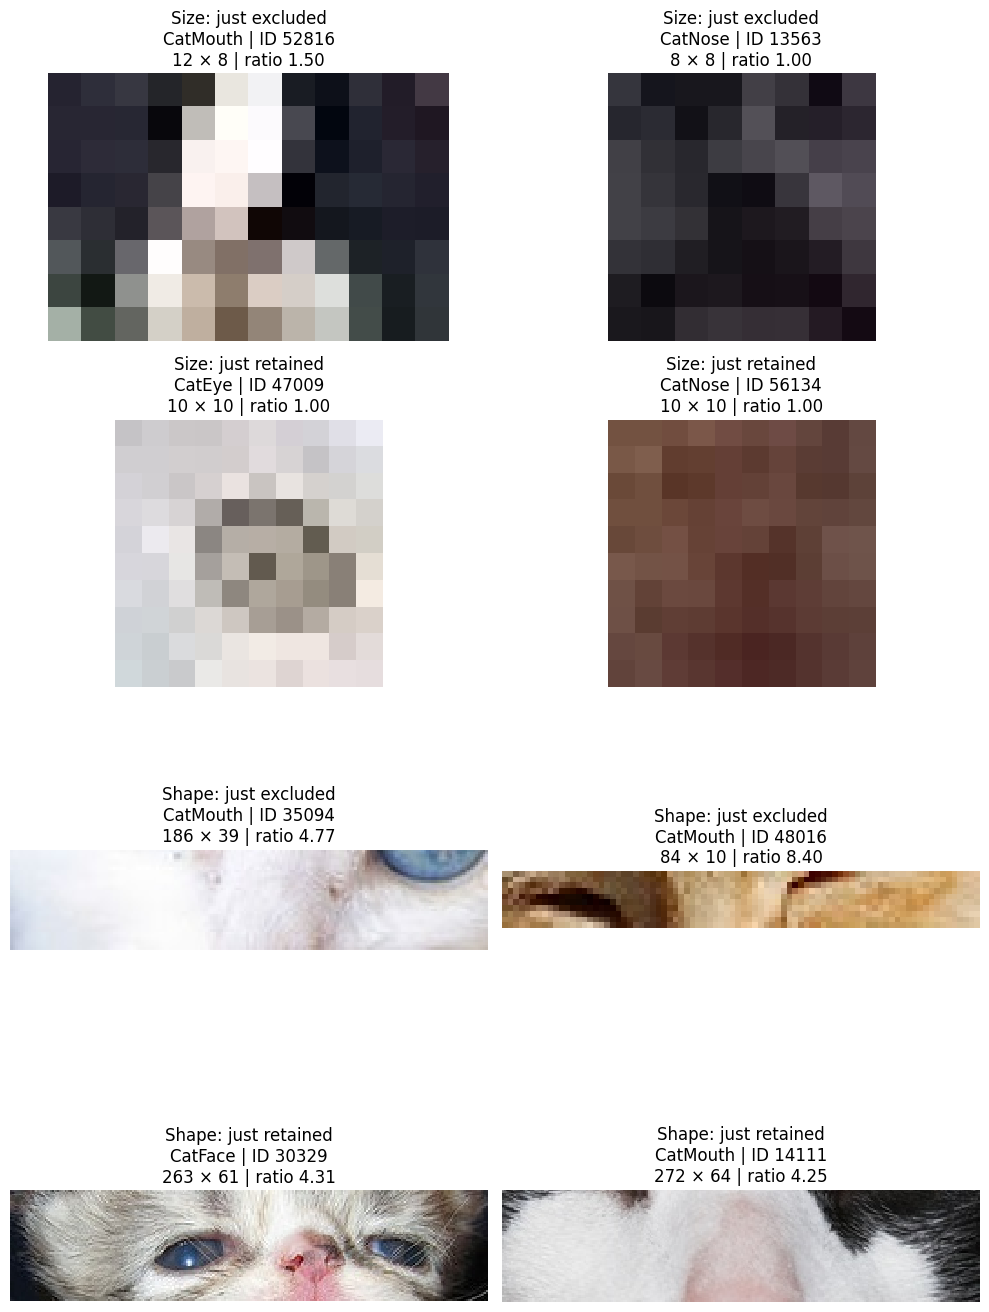

In [26]:
# Example cutoffs: exclude images below 12 pixels on their shortest side,
# or with a longest side more than four times their shortest side.
MIN_SHORT_EDGE = 10
MAX_ASPECT_RATIO = 4.5

# Match training labels to the previously recorded image dimensions.
cutoff_data = train_labels[["image_id", "class"]].merge(
    image_info[["image_id", "width", "height"]],
    on="image_id",
    how="left",
    validate="one_to_one"
)

assert cutoff_data[["width", "height"]].notna().all().all()

cutoff_data["short_edge"] = cutoff_data[["width", "height"]].min(axis=1)
cutoff_data["long_edge"] = cutoff_data[["width", "height"]].max(axis=1)
cutoff_data["aspect_ratio"] = (
    cutoff_data["long_edge"] / cutoff_data["short_edge"]
)

# Count how many images each possible cutoff would exclude.
counts = []

for threshold in [8, 12, 16, 24, 32]:
    excluded = cutoff_data["short_edge"] < threshold
    counts.append({
        "rule": f"Shortest edge < {threshold} pixels",
        "excluded": int(excluded.sum()),
        "percent": round(100 * excluded.mean(), 2)
    })

for threshold in [2, 3, 4, 5]:
    excluded = cutoff_data["aspect_ratio"] > threshold
    counts.append({
        "rule": f"Longest / shortest edge > {threshold}",
        "excluded": int(excluded.sum()),
        "percent": round(100 * excluded.mean(), 2)
    })

display(pd.DataFrame(counts))

# Apply both selected rules for counting only.
# Exactly 12 pixels passes the size rule; exactly 4 passes the shape rule.
too_small = cutoff_data["short_edge"] < MIN_SHORT_EDGE
too_rectangular = cutoff_data["aspect_ratio"] > MAX_ASPECT_RATIO
excluded = too_small | too_rectangular

# Show exclusions by class without counting overlapping exclusions twice.
class_summary = cutoff_data.assign(
    too_small=too_small,
    too_rectangular=too_rectangular,
    excluded=excluded
).groupby("class").agg(
    original_count=("image_id", "size"),
    too_small=("too_small", "sum"),
    too_rectangular=("too_rectangular", "sum"),
    excluded_total=("excluded", "sum")
)

class_summary["remaining"] = (
    class_summary["original_count"] - class_summary["excluded_total"]
)

print("Effect of the selected cutoffs:")
display(class_summary)
print("Total excluded:", int(excluded.sum()))
print("Total remaining:", int((~excluded).sum()))
print("Images meeting both exclusion rules:", int(
    (too_small & too_rectangular).sum()
))

# Select two images nearest each cutoff on each side of the boundary.
boundary_groups = [
    (
        "Size: just excluded",
        cutoff_data[too_small].nlargest(2, "short_edge")
    ),
    (
        "Size: just retained",
        cutoff_data[~too_small].nsmallest(2, "short_edge")
    ),
    (
        "Shape: just excluded",
        cutoff_data[too_rectangular].nsmallest(2, "aspect_ratio")
    ),
    (
        "Shape: just retained",
        cutoff_data[~too_rectangular].nlargest(2, "aspect_ratio")
    )
]

fig, axes = plt.subplots(4, 2, figsize=(10, 14), squeeze=False)

for row, (heading, examples) in enumerate(boundary_groups):
    for col in range(2):
        ax = axes[row, col]
        ax.axis("off")

        if col >= len(examples):
            ax.set_title(f"{heading}\nNo additional example")
            continue

        example = examples.iloc[col]
        image_path = train_dir / f"{example['image_id']}.jpg"

        with Image.open(image_path) as image:
            ax.imshow(image.convert("RGB"), interpolation="nearest")

        ax.set_title(
            f"{heading}\n"
            f"{example['class']} | ID {example['image_id']}\n"
            f"{int(example['width'])} × {int(example['height'])} | "
            f"ratio {example['aspect_ratio']:.2f}"
        )

plt.tight_layout()
plt.show()

I inspected images with very short edges and extreme aspect ratios because I was concerned about their quality and possible effect on training. The selected cutoffs flagged only 18 training images, so I decided to keep them for the first run rather than apply further exclusions; the effect of removing them has not been tested.

In [28]:
# Prepare images by stretching to 128 x 128 and scaling pixels to 0-1.
IMAGE_SIZE = 128

# Training only: mirror some images and apply small random rotations.
train_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees=10, fill=0),
    transforms.ToTensor()
])

# Validation uses the same resize and scaling, without random augmentation.
val_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor()
])

# Check both preparations on one training image without changing the file.
with Image.open(train_dir / f"{train_labels.iloc[0]['image_id']}.jpg") as source:
    sample_image = source.convert("RGB")
    training_preview = train_transform(sample_image)
    validation_preview = val_transform(sample_image)

assert training_preview.shape == (3, IMAGE_SIZE, IMAGE_SIZE)
assert validation_preview.shape == (3, IMAGE_SIZE, IMAGE_SIZE)
print("Image preparation ready: stretch to 128 x 128.")
print("Training tensor shape:", tuple(training_preview.shape))
print("Validation tensor shape:", tuple(validation_preview.shape))
print("Validation pixel range:", validation_preview.min().item(), validation_preview.max().item())

Image preparation ready: stretch to 128 x 128.
Training tensor shape: (3, 128, 128)
Validation tensor shape: (3, 128, 128)
Validation pixel range: 0.0 1.0


In [30]:

# Load images only when needed and group them into batches of 32.
BATCH_SIZE = 32

class FacialFeatureDataset(Dataset):
    def __init__(self, label_table, image_dir, transform):
        self.rows = label_table.reset_index(drop=True).copy()
        self.image_dir = image_dir
        self.transform = transform

    def __len__(self):
        return len(self.rows)

    def __getitem__(self, index):
        row = self.rows.iloc[index]
        image_path = self.image_dir / f"{row['image_id']}.jpg"
        with Image.open(image_path) as source:
            image = self.transform(source.convert("RGB"))
        return image, int(row["label"])

train_dataset = FacialFeatureDataset(train_labels, train_dir, train_transform)
val_dataset = FacialFeatureDataset(val_labels, train_dir, val_transform)

# A fixed seed makes the shuffled order repeatable across fresh runs.
loader_generator = torch.Generator().manual_seed(42)
train_loader = DataLoader(
    train_dataset, batch_size=BATCH_SIZE, shuffle=True,
    num_workers=0, generator=loader_generator
)
val_loader = DataLoader(
    val_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=0
)

# Check one batch; this does not train a model.
images, targets = next(iter(train_loader))
assert images.shape == (BATCH_SIZE, 3, IMAGE_SIZE, IMAGE_SIZE)
assert targets.dtype == torch.int64
assert targets.min().item() >= 0 and targets.max().item() < 8
assert torch.isfinite(images).all()
print("Training images:", len(train_dataset))
print("Validation images:", len(val_dataset))
print("Batch image shape:", tuple(images.shape))
print("Batch label shape:", tuple(targets.shape))
print("Batch loading check passed.")

Training images: 50916
Validation images: 12729
Batch image shape: (32, 3, 128, 128)
Batch label shape: (32,)
Batch loading check passed.


In [32]:
# Build a small CNN from scratch: three feature blocks and eight class scores.
from torch import nn

# Fix the starting random weights for repeatable fresh runs.
torch.manual_seed(42)

class CustomCNN(nn.Module):
    def __init__(self, num_classes=8):
        super().__init__()
        self.features = nn.Sequential(
            # Learn 32 feature channels from the three RGB channels.
            nn.Conv2d(3, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),
            # Increase feature channels while reducing spatial size.
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),
            # Summarise each feature channel using a 4 x 4 grid.
            nn.AdaptiveAvgPool2d((4, 4))
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(128 * 4 * 4, 128),
            nn.ReLU(),
            nn.Dropout(p=0.3),
            nn.Linear(128, num_classes)
        )

    def forward(self, images):
        return self.classifier(self.features(images))

model = CustomCNN(num_classes=len(class_names))

# Check two images without updating weights or applying dropout.
model.eval()
with torch.no_grad():
    sample_scores = model(images[:2])
assert sample_scores.shape == (2, 8)
assert torch.isfinite(sample_scores).all()
model.train()

print(model)
print("Trainable parameters:", sum(p.numel() for p in model.parameters() if p.requires_grad))
print("Output shape for two images:", tuple(sample_scores.shape))
print("CNN shape check passed; no training has started.")
# Output scores are logits; the training loss will handle their conversion.


CustomCNN(
  (features): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (6): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (7): ReLU()
    (8): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (9): AdaptiveAvgPool2d(output_size=(4, 4))
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=2048, out_features=128, bias=True)
    (2): ReLU()
    (3): Dropout(p=0.3, inplace=False)
    (4): Linear(in_features=128, out_features=8, bias=True)
  )
)
Trainable parameters: 356552
Output shape for two images: (2, 8)
CNN shape check passed; no training has started.


In [33]:
# Preserve the split and completed data checks before changing the runtime.
cache_dir = Path("/kaggle/working/preparation")
cache_dir.mkdir(parents=True, exist_ok=True)
train_labels.to_csv(cache_dir / "train_split.csv", index=False)
val_labels.to_csv(cache_dir / "validation_split.csv", index=False)
image_info.to_csv(cache_dir / "image_dimensions.csv", index=False)
labels.to_csv(cache_dir / "labels_with_hashes.csv", index=False)

# Check whether this PyTorch session can train on an NVIDIA GPU.
print("Preparation tables saved in:", cache_dir)
print("PyTorch version:", torch.__version__)
print("CUDA build:", torch.version.cuda)
print("GPU available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("GPU is not ready. Preserve the saved tables before changing the session.")
# This cell does not train the CNN.


Preparation tables saved in: /kaggle/working/preparation
PyTorch version: 2.11.0+cpu
CUDA build: None
GPU available: False
GPU is not ready. Preserve the saved tables before changing the session.


In [2]:

# Restore saved preparation tables and confirm GPU access after a session restart.
from pathlib import Path
import pandas as pd
import torch
from PIL import Image
from torchvision import transforms
from torch.utils.data import Dataset, DataLoader

print("PyTorch version:", torch.__version__)
print("GPU available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

cache_dir = Path("/kaggle/working/preparation")
if not (cache_dir / "train_split.csv").is_file():
    candidates = list(Path("/kaggle/input").rglob("train_split.csv"))
    if len(candidates) != 1:
        raise FileNotFoundError("Attach the saved notebook output containing preparation/train_split.csv, then rerun this cell.")
    cache_dir = candidates[0].parent

train_labels = pd.read_csv(cache_dir / "train_split.csv", dtype={"image_id": str})
val_labels = pd.read_csv(cache_dir / "validation_split.csv", dtype={"image_id": str})
image_info = pd.read_csv(cache_dir / "image_dimensions.csv", dtype={"image_id": str})
labels = pd.read_csv(cache_dir / "labels_with_hashes.csv", dtype={"image_id": str})
class_names = sorted(train_labels["class"].unique())
class_to_index = {name: index for index, name in enumerate(class_names)}
for table in (train_labels, val_labels):
    table["label"] = table["class"].map(class_to_index)
    assert table["label"].notna().all()
assert set(train_labels["image_hash"]).isdisjoint(val_labels["image_hash"])

first_filename = train_labels.iloc[0]["image_id"] + ".jpg"
folders = [p for p in Path("/kaggle/input").rglob("train") if p.is_dir() and (p / first_filename).is_file()]
assert len(folders) == 1, "Expected one training image folder."
train_dir = folders[0]
print("Restored training rows:", len(train_labels))
print("Restored validation rows:", len(val_labels))
print("Preparation restored without rescanning images.")


PyTorch version: 2.11.0+cu128
GPU available: True
GPU: Tesla T4
Restored training rows: 50916
Restored validation rows: 12729
Preparation restored without rescanning images.


In [3]:
# Recreate the agreed pipeline in the fresh GPU session and test three batches.
from torch import nn
import random
import numpy as np
import time
import copy

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)
IMAGE_SIZE = 128
BATCH_SIZE = 32
device = torch.device("cuda:0")
assert torch.cuda.is_available(), "A GPU is required for this trial."

train_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees=10, fill=0),
    transforms.ToTensor()
])
val_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)), transforms.ToTensor()
])

class FacialFeatureDataset(Dataset):
    def __init__(self, label_table, image_dir, transform):
        self.rows = label_table.reset_index(drop=True).copy()
        self.image_dir = image_dir
        self.transform = transform
    def __len__(self):
        return len(self.rows)
    def __getitem__(self, index):
        row = self.rows.iloc[index]
        with Image.open(self.image_dir / f"{row['image_id']}.jpg") as source:
            image = self.transform(source.convert("RGB"))
        return image, int(row["label"])

train_dataset = FacialFeatureDataset(train_labels, train_dir, train_transform)
val_dataset = FacialFeatureDataset(val_labels, train_dir, val_transform)
loader_generator = torch.Generator().manual_seed(SEED)
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True,
                          num_workers=0, generator=loader_generator)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)

class CustomCNN(nn.Module):
    def __init__(self, num_classes=8):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 32, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(32, 64, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(64, 128, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.AdaptiveAvgPool2d((4, 4))
        )
        self.classifier = nn.Sequential(
            nn.Flatten(), nn.Linear(128 * 4 * 4, 128), nn.ReLU(),
            nn.Dropout(0.3), nn.Linear(128, num_classes)
        )
    def forward(self, images):
        return self.classifier(self.features(images))

model = CustomCNN(len(class_names)).to(device)

# Train a temporary copy so the real model keeps its original starting weights.
trial_model = copy.deepcopy(model)
criterion = nn.CrossEntropyLoss()
trial_optimizer = torch.optim.Adam(trial_model.parameters(), lr=0.001)
trial_model.train()
torch.cuda.synchronize()
trial_start = time.perf_counter()
trial_iterator = iter(train_loader)
for batch_number in range(3):
    batch_images, batch_targets = next(trial_iterator)
    batch_images = batch_images.to(device)
    batch_targets = batch_targets.to(device)
    trial_optimizer.zero_grad(set_to_none=True)
    scores = trial_model(batch_images)
    loss = criterion(scores, batch_targets)
    assert torch.isfinite(loss), "Non-finite training loss."
    loss.backward()
    trial_optimizer.step()
    print(f"Trial batch {batch_number + 1}/3 completed; loss: {loss.item():.4f}")
torch.cuda.synchronize()
print("Three-batch trial seconds:", round(time.perf_counter() - trial_start, 2))
print("GPU:", torch.cuda.get_device_name(0))
print("Trial passed. Main model has not been trained.")
del trial_model, trial_optimizer, trial_iterator
loader_generator.manual_seed(SEED)
torch.manual_seed(SEED)
torch.cuda.empty_cache()


Trial batch 1/3 completed; loss: 2.0643
Trial batch 2/3 completed; loss: 2.0802
Trial batch 3/3 completed; loss: 2.0718
Three-batch trial seconds: 6.42
GPU: Tesla T4
Trial passed. Main model has not been trained.


In [4]:
# Train the custom CNN, validate after each epoch, and save the best checkpoint.
from tqdm.auto import tqdm
from datetime import datetime
import json

MAX_EPOCHS = 20
PATIENCE = 3
LEARNING_RATE = 0.001
WEIGHT_DECAY = 0.0001

# Start a fresh, repeatable run; this does not continue the temporary trial.
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)
loader_generator.manual_seed(SEED)
model = CustomCNN(len(class_names)).to(device)
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)
run_dir = Path("/kaggle/working/runs") / datetime.now().strftime("custom_cnn_%Y%m%d_%H%M%S")
run_dir.mkdir(parents=True, exist_ok=False)
config = dict(model="CustomCNN", image_size=IMAGE_SIZE, batch_size=BATCH_SIZE,
              learning_rate=LEARNING_RATE, weight_decay=WEIGHT_DECAY,
              max_epochs=MAX_EPOCHS, patience=PATIENCE, seed=SEED,
              class_to_index=class_to_index, torch_version=str(torch.__version__))
(run_dir / "config.json").write_text(json.dumps(config, indent=2))
train_labels.to_csv(run_dir / "train_split.csv", index=False)
val_labels.to_csv(run_dir / "validation_split.csv", index=False)
history = []
best_val_loss = float("inf")
stale_epochs = 0
print("Run outputs:", run_dir, flush=True)

for epoch in range(1, MAX_EPOCHS + 1):
    epoch_start = time.perf_counter()
    model.train()
    train_loss_sum, train_correct, train_count = 0.0, 0, 0
    progress = tqdm(train_loader, desc=f"Epoch {epoch}/{MAX_EPOCHS}: training")
    for batch_images, batch_targets in progress:
        batch_images, batch_targets = batch_images.to(device), batch_targets.to(device)
        optimizer.zero_grad(set_to_none=True)
        scores = model(batch_images)
        loss = criterion(scores, batch_targets)
        if not torch.isfinite(loss):
            raise RuntimeError("Training loss became non-finite.")
        loss.backward()
        optimizer.step()
        count = batch_targets.size(0)
        train_count += count
        train_loss_sum += loss.item() * count
        train_correct += (scores.argmax(1) == batch_targets).sum().item()
        progress.set_postfix(loss=f"{train_loss_sum / train_count:.4f}")

    # Validation checks the held-out images without updating the model.
    model.eval()
    val_loss_sum, val_correct, val_count = 0.0, 0, 0
    with torch.no_grad():
        for batch_images, batch_targets in tqdm(val_loader, desc="Validation"):
            batch_images, batch_targets = batch_images.to(device), batch_targets.to(device)
            scores = model(batch_images)
            loss = criterion(scores, batch_targets)
            if not torch.isfinite(loss):
                raise RuntimeError("Validation loss became non-finite.")
            count = batch_targets.size(0)
            val_count += count
            val_loss_sum += loss.item() * count
            val_correct += (scores.argmax(1) == batch_targets).sum().item()

    row = dict(epoch=epoch, train_loss=train_loss_sum / train_count,
               train_accuracy=train_correct / train_count,
               val_loss=val_loss_sum / val_count, val_accuracy=val_correct / val_count,
               seconds=time.perf_counter() - epoch_start)
    history.append(row)
    pd.DataFrame(history).to_csv(run_dir / "history.csv", index=False)
    checkpoint = dict(epoch=epoch, model_state=model.state_dict(),
                      optimizer_state=optimizer.state_dict(), config=config, history=history)
    torch.save(checkpoint, run_dir / "last.pt")
    if row["val_loss"] < best_val_loss:
        best_val_loss = row["val_loss"]
        stale_epochs = 0
        torch.save(checkpoint, run_dir / "best.pt")
    else:
        stale_epochs += 1
    print(row, flush=True)
    if stale_epochs >= PATIENCE:
        print("Early stopping: validation loss did not improve for three epochs.", flush=True)
        break

# Use the checkpoint with the lowest validation loss for later evaluation.
best_checkpoint = torch.load(run_dir / "best.pt", map_location=device, weights_only=True)
model.load_state_dict(best_checkpoint["model_state"])
model.eval()
print("Training finished. Best checkpoint epoch:", best_checkpoint["epoch"])
print("Preserve the run output files before ending the session:", run_dir)


Run outputs: /kaggle/working/runs/custom_cnn_20261022_035501


Epoch 1/20: training:   0%|          | 0/1592 [00:00<?, ?it/s]

Validation:   0%|          | 0/398 [00:00<?, ?it/s]

{'epoch': 1, 'train_loss': 1.2406835213171283, 'train_accuracy': 0.5335650875952549, 'val_loss': 0.5706823234687719, 'val_accuracy': 0.8054049807526121, 'seconds': 3254.2189850430004}


Epoch 2/20: training:   0%|          | 0/1592 [00:00<?, ?it/s]

...

Validation:   0%|          | 0/398 [00:00<?, ?it/s]

{'epoch': 15, 'train_loss': 0.1325976608919893, 'train_accuracy': 0.9561238117684029, 'val_loss': 0.09321989152679712, 'val_accuracy': 0.968968497132532, 'seconds': 161.3668130340002}


Epoch 16/20: training:   0%|          | 0/1592 [00:00<?, ?it/s]

Validation:   0%|          | 0/398 [00:00<?, ?it/s]

{'epoch': 16, 'train_loss': 0.12501986199557213, 'train_accuracy': 0.9581074711289183, 'val_loss': 0.10134504527592239, 'val_accuracy': 0.9667687956634456, 'seconds': 162.63699510200058}
Early stopping: validation loss did not improve for three epochs.
Training finished. Best checkpoint epoch: 13
Preserve the run output files before ending the session: /kaggle/working/runs/custom_cnn_20261022_035501
